# <font style="color:blue">Project 3: Object Detection</font>



# Dataset 


This project uses the Vehicle Registration Plate dataset from [Open Images Dataset](https://storage.googleapis.com/openimages/web/index.html)


The task is a single class object detection problem :  `vehicle registration plate detection`


The dataset has the following structure:

```
Dataset
├── train
│   └── Vehicle registration plate
│       └── Label
└── validation
    └── Vehicle registration plate
        └── Label
```

The train and validation directories contain the images and their corresponding annotations.

Each Vehicle registration plate directory contains .jpg images and a Label folder with the corresponding .txt annotation files.

```
Example:

Image: Dataset/train/Vehicle registration plate/bf4689922cdfd532.jpg
Annotation: Dataset/train/Vehicle registration plate/Label/bf4689922cdfd532.txt
```


Each .txt file may contain one or more lines, with each line representing a bounding box.

```
Example:

Vehicle registration plate 385.28 445.15 618.24 514.225
Vehicle registration plate 839.68 266.066462 874.24 289.091462
```

The original annotations use the following bounding box format:: `xmin, ymin, xmax, ymax`

The original dataset contains 5,308 training images and 386 validation images.


Note: The dataset structure and annotations were subsequently adapted for this project. The addition of a test set and the conversion to YOLO format are described in the dataset preparation section below.

In [175]:
import os
import random
from glob import glob

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from PIL import Image
from IPython.display import YouTubeVideo, display
from ultralytics import YOLO, settings

# Exploratory Analysis of Ground-Truth Bounding Boxes

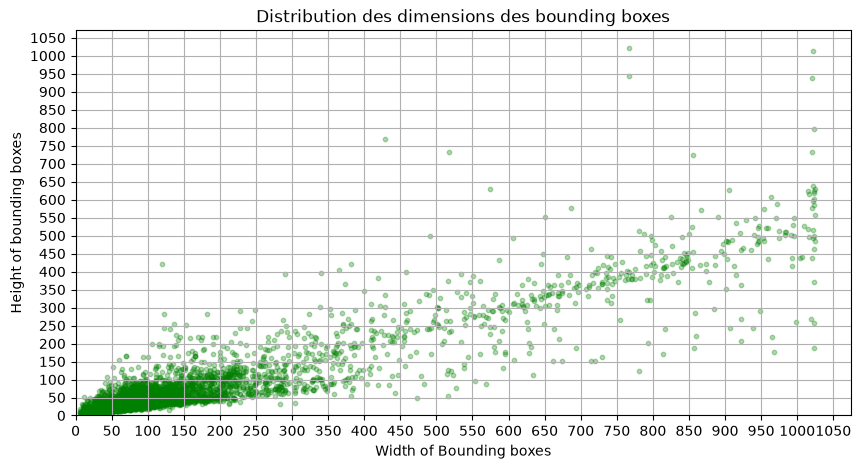

In [176]:
list_file_train=glob(os.path.join("Dataset","train","**","labels_standard","*.txt"),recursive=True)
dim_bbox=[]
for i in list_file_train:
    with open(i) as f_t:
        dim_bbox.append(f_t.read().rstrip().split(" ")[-4:])

dim_bbox=np.array([list(map(float,bbox)) for bbox in dim_bbox])

W=dim_bbox[:,2] - dim_bbox[:,0]
H=dim_bbox[:,3] - dim_bbox[:,1]

#computer 
plt.figure(figsize=(10,5))
plt.scatter(W,H,alpha=0.3,c="g",s=10)

plt.xlim(0, max(W)+50)
plt.ylim(0, max(H)+50)
plt.xticks(range(0, int(max(W)) + 51, 50))
plt.yticks(range(0, int(max(H)) + 51, 50))

plt.xlabel("Width of Bounding boxes")
plt.ylabel("Height of bounding boxes")
plt.title("Distribution des dimensions des bounding boxes")

plt.grid(True)
plt.show()

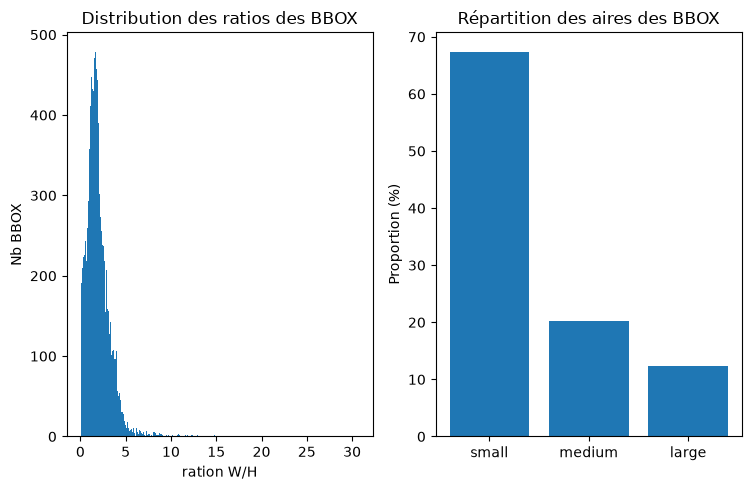

small : 7157 bounding boxes (67.42)%
medium : 2154 bounding boxes (20.29)%
large : 1305 bounding boxes (12.29)%


In [245]:
#W=r*H
ratio=W/H
aire=W*H
area_32x32=1024
area_96x96=9216

small= np.sum(aire<area_32x32)
medium= np.sum((aire>=area_32x32) & (aire<=area_96x96))
large= np.sum(aire>area_96x96)


label=["small","medium","large"]
counts=[small,medium,large]
proportion=(np.array(counts)/len(aire))*100

plt.figure(figsize=(15,5))
plt.subplot(1,4,1)
plt.hist(ratio,bins=300)
plt.title("Distribution des ratios des BBOX")
plt.xlabel("ration W/H")
plt.ylabel("Nb BBOX")

plt.subplot(1,4,2)
plt.bar(label,proportion)
plt.ylabel("Proportion (%)")
plt.title("Répartition des aires des BBOX")
plt.tight_layout()
plt.show()


for LABEL,COUNT,PROP in zip(label,counts,proportion):
    print(f"{LABEL} : {COUNT } bounding boxes ({PROP:.2f})%")

#On can see in the barplot, that bbox smaller is more than other bbox "medium and large"


# Visualizing Ground-Truth Bounding Boxes

In [202]:
dic_class_color={"Vehicle registration plate": (0, 0, 255)} 



def plot_box(image, bboxes, labels):
    for box_num, box in enumerate(bboxes):
        xmin,ymin,xmax, ymax=box
        xmin=int(xmin)
        ymin=int(ymin)
        xmax=int(xmax)
        ymax=int(ymax)
                        
        cv2.rectangle(
            image, 
            (xmin,ymin),(xmax,ymax),
            color=dic_class_color[labels[box_num]],
            thickness=2
        )
        cv2.putText(
            image,
            text=labels[box_num],
            org=(xmin, ymin-5),
            fontFace=cv2.FONT_HERSHEY_SIMPLEX,
            fontScale=0.7,
            color=dic_class_color[labels[box_num]],
            thickness=2,
            lineType=cv2.LINE_AA
        )
    return image



# Function to plot images with the bounding boxes.
def plot(train,num_samples):
    image_paths=glob(os.path.join("Dataset",f"{train}","**",'*.jpg'),recursive=True)
    label_paths=os.path.join("Dataset",f"{train}","Vehicle registration plate","labels_standard")
    
    all_images=sorted(image_paths)
    select_image=random.sample(all_images,num_samples)
    
    
    plt.figure(figsize=(15, 12))
    
    for i,img in enumerate(select_image):
     
        image_name=os.path.basename(img).split(".")[0]
      
        image = cv2.imread(img)
       
        with open(os.path.join(label_paths, image_name+'.txt'), 'r') as f:
            bboxes = []
            labels = []
            for label_line in f:
                label_lines = label_line.rstrip().split(" ")
                    
                label = ' '.join(label_lines[:-4])
                bbox_string = label_lines[-4:]
             
                xmin, ymin, xmax, ymax = bbox_string
                xmin = float(xmin)
                ymin = float(ymin)
                xmax = float(xmax)
                ymax = float(ymax)
                bboxes.append([xmin,ymin,xmax,ymax])
                labels.append(label)
              
        result_image = plot_box(image, bboxes, labels)
        plt.subplot(2, 2, i+1)
        plt.imshow(result_image[:, :, ::-1])
        plt.axis('off')
    plt.subplots_adjust(wspace=1)
    plt.tight_layout()
    plt.show() 

    

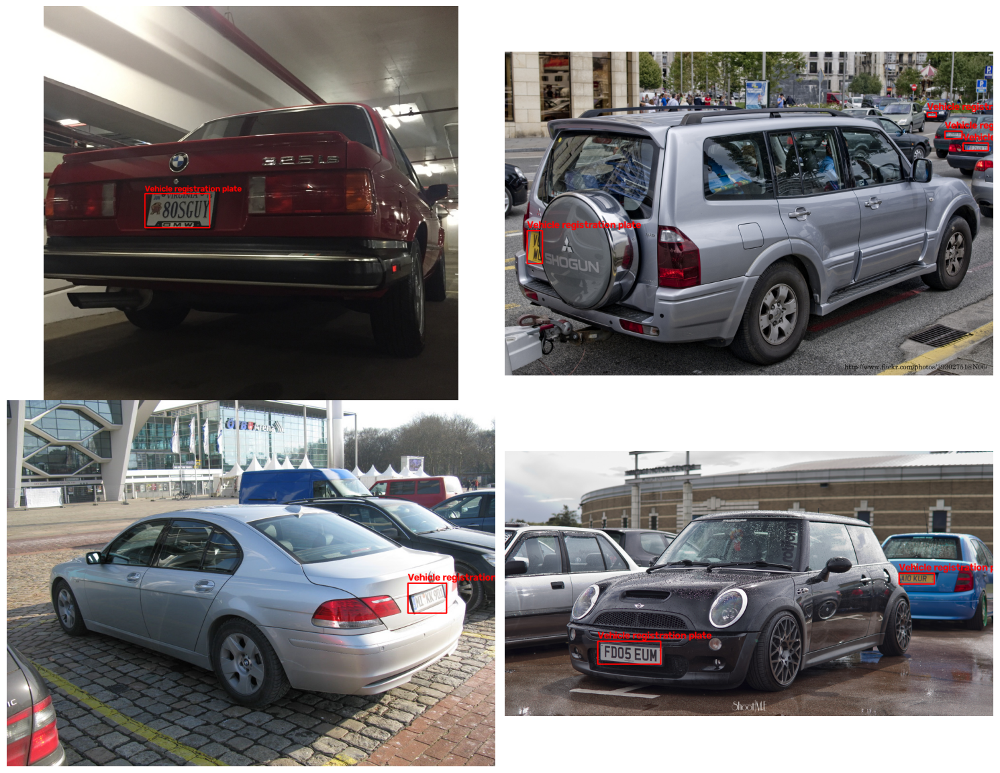

In [207]:
# Visualize a few training images.
plot("train",num_samples=4)  

# Training

In [208]:
# Load pretrained models
model_yolo26n=YOLO("yolo26n.pt")
model_yolov8n=YOLO("yolov8n.pt")
model_yolo26l=YOLO("yolo26l.pt")

# Display model information
print("YOLO26n")
print(model_yolo26n.info())

print("\nYOLOv8n")
print(model_yolov8n.info())

print("\nYOLO26l")
print(model_yolo26l.info())


YOLO26n
YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs
(260, 2572280, 0, 6.2396672)

YOLOv8n
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs
(129, 3157200, 0, 8.8550912)

YOLO26l
YOLO26l summary: 392 layers, 26,299,704 parameters, 0 gradients, 94.2 GFLOPs
(392, 26299704, 0, 94.1582336)


# Dataset Preparation: YOLO Annotation Format

In [218]:
def conver_XYXY_XYWH(train):
    print(f"Convert in progress for {train}...")
    path_label_nor=os.path.join(f"Dataset/{train}/Vehicle registration plate/labels_nor")
    if not os.path.exists(path_label_nor):
        os.makedirs(path_label_nor,exist_ok=True)

    
    image_paths=glob(os.path.join("Dataset",train,"**",'*.jpg'),recursive=True)
    label_paths=f"Dataset/{train}/Vehicle registration plate/labels"
    
    for i in image_paths:       
        image_name=os.path.basename(i).split(".")[0]
        
        H,W=cv2.imread(i).shape[:2]
        
        with open(os.path.join(label_paths, image_name+'.txt'), 'r') as fr:
            with open(os.path.join(path_label_nor, image_name+'.txt'), 'w') as fw:
                
                for label_line in fr:
                    label_lines = label_line.rstrip().split(" ")
                        
                    label = ' '.join(label_lines[:-4])
                    label_mapping=dic_label_class[label]
                    
                    bbox_string = label_lines[-4:]
                 
                    xmin, ymin, xmax, ymax = bbox_string
                    xmin = float(xmin)
                    ymin = float(ymin)
                    xmax = float(xmax)
                    ymax = float(ymax)
                    x_c = (((xmax+xmin))/2)/W
                    y_c  =(((ymax+ymin))/2)/H
                    w    =(xmax-xmin)/W
                    h    =(ymax-ymin)/H
                    text=f"{label_mapping} {x_c} {y_c} {w} {h}" 
                             
                    fw.write(text+"\n")
    print(f"Convert finish for {train}")

In [219]:
dic_label_class={"Vehicle registration plate":0}



#convert for train
conver_XYXY_XYWH("train")
#convert for validation
conver_XYXY_XYWH("validation")

for convert_dir in ("train", "validation"):
    path_labels=os.path.join(f"Dataset/{convert_dir}/Vehicle registration plate/labels")
    path_labels_save=os.path.join(f"Dataset/{convert_dir}/Vehicle registration plate/labels_standard")
    path_label_nor=os.path.join(f"Dataset/{convert_dir}/Vehicle registration plate/labels_nor")
    
    os.rename(path_labels,path_labels_save)
    os.rename(path_label_nor,path_labels)


Convert in progress for train...
Convert finish for train
Convert in progress for validation...
Convert finish for validation


# Test Set

For this project, I added a test set from the **Roboflow** [License Plate Recognition dataset](https://universe.roboflow.com/roboflow-universe-projects/license-plate-recognition-rxg4e/dataset/12?utm_source=chatgpt.com)

**Training set**: used to train the models.  
**Validation set**: used to monitor performance and compare model configurations.    
**Test set**: used for the final evaluation on unseen images.

The dataset directory structure is shown below.

In [87]:
!tree -d Dataset

Dataset
├── test
│   └── Vehicle registration plate
│       ├── images
│       └── labels
├── train
│   └── Vehicle registration plate
│       ├── images
│       ├── labels
│       └── labels_standard
└── validation
    └── Vehicle registration plate
        ├── images
        ├── labels
        └── labels_standard

15 directories


# Configure Ultralytics Settings

In [210]:
path_dir_projet=os.getcwd()+"/Dataset"
settings.update({"datasets_dir": path_dir_projet})
settings.update({"tensorboard": True})

print(settings["datasets_dir"])
print(settings["tensorboard"])

/home/maamar/OpenCV-Projet/Project 4 Object Detection/Dataset
True



(pytorch_env) maamar@DataMaamar:~/OpenCV-Projet/Project 4 Object Detection$ tensorboard --logdir "/home/maamar/OpenCV-Projet/Project 4 Object Detection/runs/detect/" --port 6010
TensorFlow installation not found - running with reduced feature set.

NOTE: Using experimental fast data loading logic. To disable, pass
    "--load_fast=false" and report issues on GitHub. More details:
    https://github.com/tensorflow/tensorboard/issues/4784

Serving TensorBoard on localhost; to expose to the network, use a proxy or pass --bind_all
TensorBoard 2.21.0 at http://localhost:6010/ (Press CTRL+C to quit)


In [212]:
# Create the YAML configuration file for YOLO
cwd = os.getcwd()

data_yaml = {
    'path': os.path.join(cwd,'Dataset'),
    'train': 'train/Vehicle registration plate',
    'val': 'validation/Vehicle registration plate',
    'test':'test/Vehicle registration plate',    
    'names': {
          0: 'Vehicle registration plate'
          
             }
       }

with open("VRP.yaml","w") as f:
    yaml.dump(data_yaml,f)

# Training YOLOv8 and YOLO26 at 320px and 640px

In [39]:
def setting_device():
    gpu=torch.cuda.is_available()
    DEVICE=0 if gpu else "cpu"
    return DEVICE,gpu
    
DEVICE,gpu=setting_device()

model_yolo26l=YOLO("yolo26l.pt")
resultats=model_yolo26l.train(data="VRP.yaml",
                              epochs=30,
                              batch=6,
                              imgsz=640, 
                              device=DEVICE,
                              name="Train_yolo26l_640px",
                              workers=6)

New https://pypi.org/project/ultralytics/8.4.186 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VRP.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l.pt, momen

/home/maamar/OpenCV-Projet/pytorch_env/lib/python3.13/site-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       1/30      5.04G      1.881      2.757   0.007205         16        640: 100% ━━━━━━━━━━━━ 885/885 3.7it/s 3:570.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 2.0it/s 16.5s0.4s
                   all        386        512      0.767      0.699      0.763       0.46

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/30      4.62G      2.024      1.361   0.008205          2        640: 100% ━━━━━━━━━━━━ 885/885 3.7it/s 3:590.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 5.3it/s 6.3s0.2s
                   all        386        512      0.841      0.661      0.772      0.437

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/30      4.54G      2.027      1.336   0.008213          9        64

## Training Experiments Overview

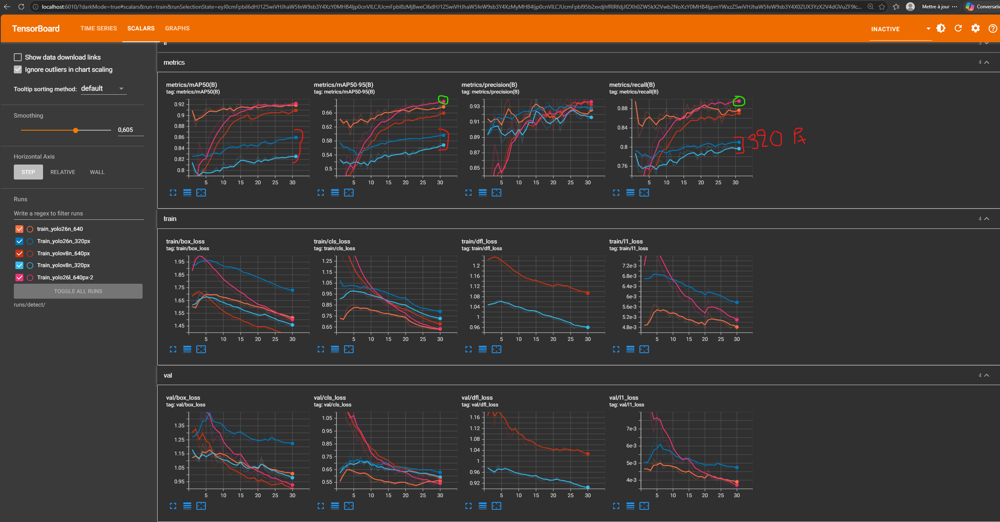

In [110]:
Image.open("train_model_YOLO.png")

FRENCH

## Analyse des résultats

On remarque qu'en augmentant la résolution des images en entrée, les performances des modèles ont globalement tendance à s'améliorer. Cela est logique, car une résolution plus élevée conserve davantage de détails visuels, ce qui peut faciliter la détection des petits objets, notamment les plaques d'immatriculation.

Sur le graphique, la courbe rouge représente les résultats obtenus avec une résolution d'entrée de **320 × 320 pixels**. Les résolutions plus élevées permettent généralement d'obtenir de meilleurs résultats, même si les gains varient selon l'architecture utilisée.

On observe également des différences entre les trois modèles testés : YOLOv8n, YOLO26n et YOLO26l. Dans mes expériences, YOLO26l obtient les meilleures performances globales sur le jeu de test, notamment pour la localisation des petits objets.

Cette différence peut notamment s'expliquer par la capacité de représentation supérieure de YOLO26l, qui possède davantage de paramètres. Son architecture peut apprendre des caractéristiques plus riches, tandis que la structure FPN combine des informations sémantiques issues des couches profondes avec des informations spatiales plus détaillées provenant des couches à haute résolution. Cette combinaison est particulièrement utile pour détecter les petits objets.

Au vu des résultats obtenus, j'ai retenu **YOLO26l**, qui offre le meilleur compromis en matière de précision de détection dans mes expérimentations, tout en tenant compte de son coût de calcul plus élevé.


---------------------------------------------------------------------------------------------------------------------------------------

ENGLISH

We can observe that increasing the input image resolution generally tends to improve model performance. This is expected, as a higher resolution preserves more visual details, which can make small objects, particularly license plates, easier to detect.

In the graph, the red curve represents the results obtained with an input resolution of **320 × 320 pixels**. Higher resolutions generally lead to better results, although the improvements vary depending on the architecture used.

Differences can also be observed between the three models tested: YOLOv8n, YOLO26n, and YOLO26l. In my experiments, YOLO26l achieves the best overall performance on the test set, particularly in terms of small-object localization.

This difference can partly be explained by YOLO26l's greater representational capacity, as it has more parameters. Its architecture can learn richer features, while the Feature Pyramid Network (FPN) combines semantic information from deeper layers with more detailed spatial information from higher-resolution layers. This combination is particularly useful for detecting small objects.

# Inference on Test Images

In [53]:
path_model_best=glob(os.path.join("runs","**","Train_yolo26l_640px-2","**","best.pt"),recursive=True)
GLOB_test=glob(os.path.join(os.getcwd(),"Dataset","test","**","*.jpg"),recursive=True)

In [58]:

load_best_model=YOLO(path_model_best[0])
load_best_model.predict(random.sample(GLOB_test,4),
                       name='yolo26l_predict',
                       exist_ok=True,
                       save=True)


0: 416x640 1 Vehicle registration plate, 14.5ms
1: 416x640 1 Vehicle registration plate, 14.5ms
2: 416x640 1 Vehicle registration plate, 14.5ms
3: 416x640 1 Vehicle registration plate, 14.5ms
Speed: 2.4ms preprocess, 14.5ms inference, 1.1ms postprocess per image at shape (1, 3, 416, 640)
Results saved to /home/maamar/OpenCV-Projet/Project 4 Object Detection/runs/detect/yolo26l_predict


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'Vehicle registration plate'}
 obb: None
 orig_img: array([[[ 89,  91, 101],
         [ 89,  91, 101],
         [ 89,  91, 101],
         ...,
         [ 16,  23,  16],
         [ 97, 104,  97],
         [222, 229, 222]],
 
        [[ 89,  91, 101],
         [ 89,  91, 101],
         [ 89,  91, 101],
         ...,
         [  2,   9,   2],
         [ 33,  40,  33],
         [122, 129, 122]],
 
        [[ 89,  91, 101],
         [ 89,  91, 101],
         [ 89,  91, 101],
         ...,
         [  0,   2,   0],
         [ 29,  33,  28],
         [126, 130, 125]],
 
        ...,
 
        [[114, 129, 132],
         [115, 130, 133],
         [115, 130, 133],
         ...,
         [ 39,  82,  85],
         [101,  93, 103],
         [113,  81,  92]],
 
        [[114, 129, 132],
         [115, 130, 133],
         [115, 130, 133],

## Visualizing Predictions

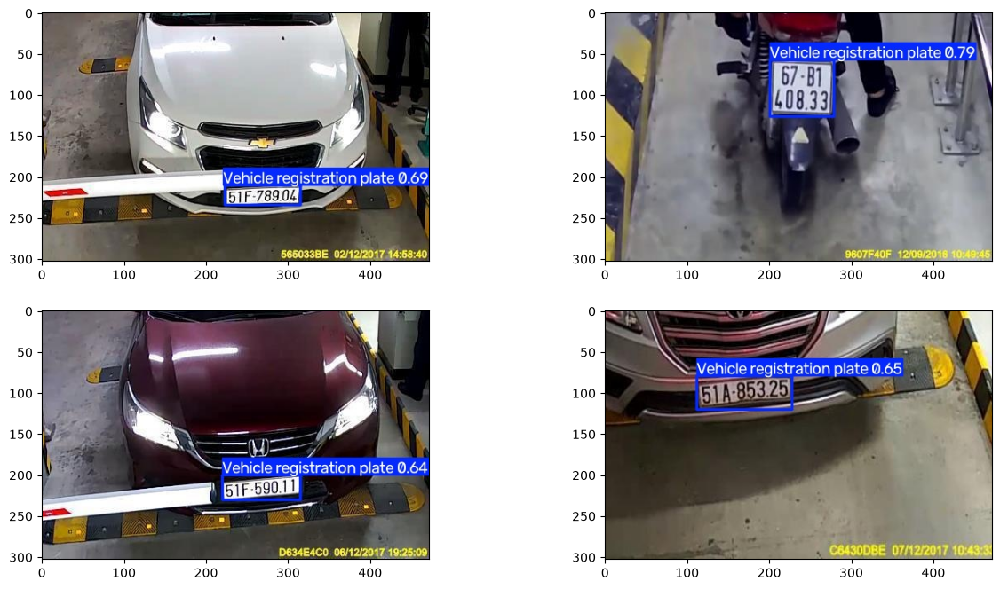

In [107]:
#GLOB_predict=glob(os.path.join(os.getcwd(),"runs","**","yolo26l_predict","*.jpg"),recursive=True)

plt.figure(figsize=(15,8))

for indice, image_name in enumerate(random.sample(GLOB_predict,4)):
    image=plt.imread(image_name)
    plt.subplot(2,2,indice+1)
    plt.imshow(image);
    

## COCO Detection Evaluation

In [85]:
glob(os.path.join("runs","**","*26*","**","best.pt"),recursive=True)

['runs/detect/Train_yolo26l_640px-2/weights/best.pt',
 'runs/detect/Train_yolo26_FT_v4_model_base26_extend_epoch_640px/weights/best.pt']

In [86]:
path_best_model=glob(os.path.join("runs","**","*26*","**","best.pt"),recursive=True)
model_best=YOLO(path_best_model[0])

metrics=model_best.val(data="VRP.yaml",
                       split="test",
                       batch=6 ,
                       imgsz=640,
                       device=DEVICE,
                       save_json=True,
                       name='test_yolo26l_640',
                       workers=6)

Ultralytics 8.4.183 🚀 Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO26l summary (fused): 188 layers, 24,746,511 parameters, 0 gradients, 86.5 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.2 ms, read: 55.5±41.7 MB/s, size: 24.5 KB)
val: Scanning /home/maamar/OpenCV-Projet/Project 4 Object Detection/Dataset/test/Vehicle registration plate/labels.cache... 1019 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1019/1019 95.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 170/170 4.5it/s 37.7s0.3ss
                   all       1019       1085      0.972      0.922      0.963      0.556
Speed: 0.6ms preprocess, 29.2ms inference, 0.0ms loss, 1.3ms postprocess per image
Saving /home/maamar/OpenCV-Projet/Project 4 Object Detection/runs/detect/test_yolo26l_640/predictions.json...

Evaluating faster-coco-eval mAP...
Evaluate annotation type *bbox*
COCOeval_opt.evaluate() finished...

## Test Set Prediction Visualization

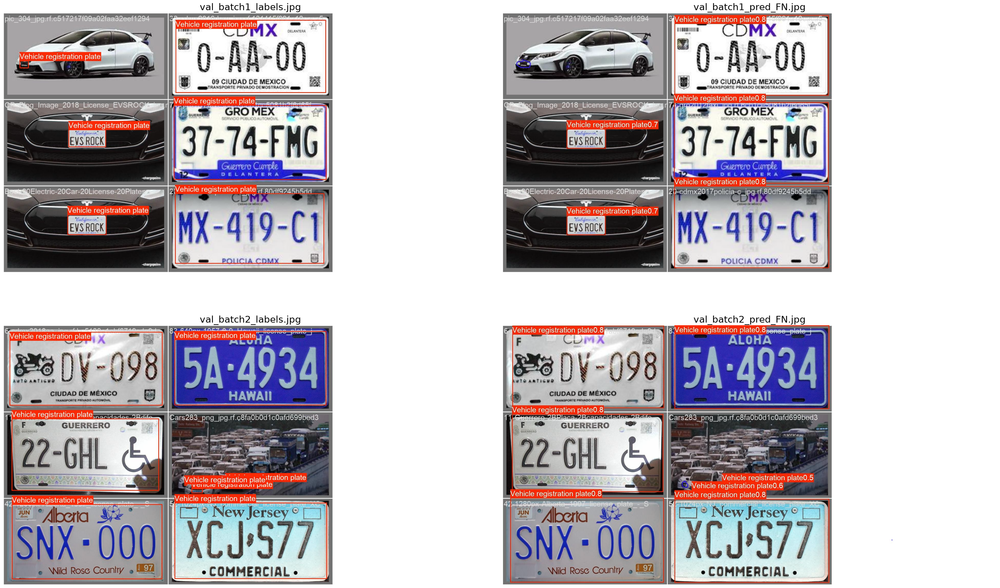

In [162]:

glob_batch=sorted(glob(os.path.join('val_batch*')))
plt.figure(figsize=(30, 20))

for idx,img in enumerate(glob_batch,start=1):
   
    image=cv2.imread(img)
    plt.subplot(2,2,idx)
    plt.imshow(image)
    plt.title(img,fontsize=20)
    plt.axis("off")

plt.tight_layout()

The test set obtained from Roboflow may differ from the validation set in terms of image characteristics and acquisition conditions. This could explain some of the differences in performance. Although precision, recall, and mAP@50 are higher on the test set, mAP@50–95 is lower than on the validation set, suggesting less accurate localization under stricter IoU thresholds.

As shown in the qualitative examples above, some very small license plates were not detected, which may have contributed to these results. However, the displayed images represent only a small sample of the test-set predictions and do not reflect the model's overall performance on their own.




FRENCH

### Analyse qualitative des petites plaques

La comparaison des annotations (*labels*) avec les prédictions du modèle sur le jeu de test met en évidence des plaques de très petite taille qui n'ont pas été détectées, notamment dans les images `pic_304` et `Cars283`.

Ces observations illustrent la difficulté du modèle à détecter certains petits objets. Elles sont cohérentes avec la faible valeur de `AP_small` obtenue lors de l'évaluation COCOeval.

La petite taille des plaques constitue une explication possible : elles occupent peu de pixels dans l'image, ce qui rend leur détection et leur localisation plus difficiles.

---------------------------------------------------------------------------------------------------------------------------------------------------

ENGLISH
### Qualitative Analysis of Small License Plates

Comparing the ground-truth annotations (*labels*) with the model's predictions on the test set reveals several very small license plates that were not detected, particularly in the images `pic_304` and `Cars283`.

These examples illustrate the model's difficulty in detecting certain small objects. They are consistent with the low `AP_small` value obtained during COCO evaluation.

The small size of the license plates is a possible contributing factor: they occupy very few pixels in the image, making them more difficult to detect and localize accurately.

# Video Inference

In [95]:
predict_video=model_best.predict('car.mp4',
                   name='yolo26l_predict_video_bis',
                   exist_ok=True,
                   save=True,
                  stream=True)

for pr in predict_video:
    pass


video 1/1 (frame 1/631) /home/maamar/OpenCV-Projet/Project 4 Object Detection/car.mp4: 416x640 2 Vehicle registration plates, 204.3ms
video 1/1 (frame 2/631) /home/maamar/OpenCV-Projet/Project 4 Object Detection/car.mp4: 416x640 2 Vehicle registration plates, 29.6ms
video 1/1 (frame 3/631) /home/maamar/OpenCV-Projet/Project 4 Object Detection/car.mp4: 416x640 2 Vehicle registration plates, 30.1ms
video 1/1 (frame 4/631) /home/maamar/OpenCV-Projet/Project 4 Object Detection/car.mp4: 416x640 2 Vehicle registration plates, 35.0ms
video 1/1 (frame 5/631) /home/maamar/OpenCV-Projet/Project 4 Object Detection/car.mp4: 416x640 2 Vehicle registration plates, 29.5ms
video 1/1 (frame 6/631) /home/maamar/OpenCV-Projet/Project 4 Object Detection/car.mp4: 416x640 2 Vehicle registration plates, 31.7ms
video 1/1 (frame 7/631) /home/maamar/OpenCV-Projet/Project 4 Object Detection/car.mp4: 416x640 2 Vehicle registration plates, 29.1ms
video 1/1 (frame 8/631) /home/maamar/OpenCV-Projet/Project 4 Object

In [92]:
predict_video=model_best.predict('projet3-input-video.mp4',
                   name='yolo26l_predict_video',
                   exist_ok=True,
                   save=True,
                  stream=True)

for pr in predict_video:
    pass


video 1/1 (frame 1/131) /home/maamar/OpenCV-Projet/Project 4 Object Detection/projet3-input-video.mp4: 384x640 (no detections), 196.7ms
video 1/1 (frame 2/131) /home/maamar/OpenCV-Projet/Project 4 Object Detection/projet3-input-video.mp4: 384x640 (no detections), 32.8ms
video 1/1 (frame 3/131) /home/maamar/OpenCV-Projet/Project 4 Object Detection/projet3-input-video.mp4: 384x640 (no detections), 28.1ms
video 1/1 (frame 4/131) /home/maamar/OpenCV-Projet/Project 4 Object Detection/projet3-input-video.mp4: 384x640 (no detections), 32.2ms
video 1/1 (frame 5/131) /home/maamar/OpenCV-Projet/Project 4 Object Detection/projet3-input-video.mp4: 384x640 (no detections), 28.8ms
video 1/1 (frame 6/131) /home/maamar/OpenCV-Projet/Project 4 Object Detection/projet3-input-video.mp4: 384x640 (no detections), 27.9ms
video 1/1 (frame 7/131) /home/maamar/OpenCV-Projet/Project 4 Object Detection/projet3-input-video.mp4: 384x640 (no detections), 28.4ms
video 1/1 (frame 8/131) /home/maamar/OpenCV-Projet/Pr

# Video Demonstrations

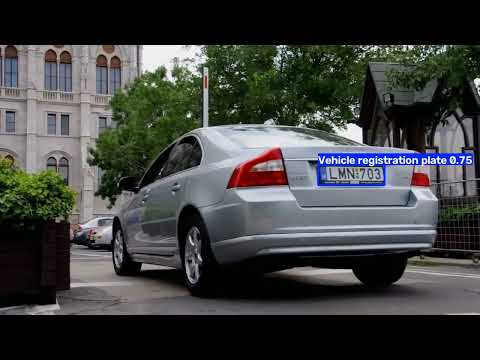

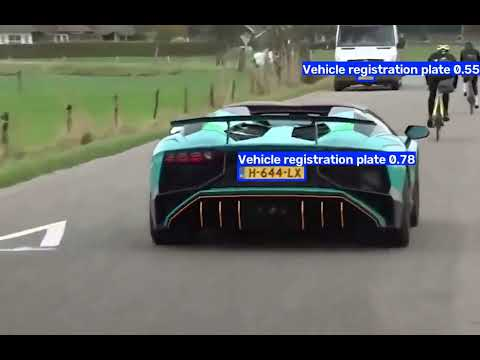

In [174]:
# Video 1: première démonstration with YOLO26l
video1 = YouTubeVideo("X3PUhNaNzmo", width=640, height=360)
display(video1)

# I take other video for detection plate
#Video 2: License Plate Detection with YOLO26l
video2 = YouTubeVideo("FTYfAgQp3Mg", width=640, height=360)
display(video2)